# Holocene Miyake Event Re-Analysis and Epoch-Local Fluence Scaling

Six rapid cosmic-ray radiocarbon production excursions – spanning nearly nine millennia from `7176 BCE` to `993 CE` – are bundled in `ticktack 2.0`'s audited dataset catalogue alongside `IntCal20`. Re-analysing these events homogeneously requires resolving three systematic effects that biased legacy `ticktack 1.x` workflows: proleptic astronomical year conversion across the `1 BCE -> 1 CE` boundary (`historical_bce`, mapping historical year `Y BCE` to astronomical year `-(Y - 1)`), Southern Hemisphere Austral summer growth windows (`october-march` under both Schulman start-year and completion-year conventions) coupled to `Brehm21`'s `4.39‰` inter-hemispheric steady-state gradient, and the distinction between 1950 CE oxalic-acid standard yield (`relative_to="standard"`) and epoch-local ambient yield (`relative_to="ambient"`) when mid-Holocene atmospheric radiocarbon stood `+78‰` to `+90‰` above pre-industrial levels.

In [1]:
import math
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import tinygp.kernels as tk
from tqdm.auto import tqdm
import ticktack as tt

cbm = tt.load_preset("Brehm21")
steady_model = tt.RadiocarbonModel(cbm, tt.SteadyProduction())
nh_sh_grad = float(
    steady_model.predict_fine([770.0], hemisphere="north")[0]
    - steady_model.predict_fine([770.0], hemisphere="south")[0]
)
EVENTS = ("775CE", "993CE", "660BCE", "5259BCE", "5410BCE", "7176BCE")
datasets = {ev: tt.load_bundled_event(ev) for ev in EVENTS}
lines = [f"Brehm21 steady-state NH - SH gradient: {nh_sh_grad:.3f} permil", "-" * 68]
for ev, ds in datasets.items():
    t0, t1 = ds.time_span
    cal = ds.series[0].calendar
    lines.append(
        f"{ev:7s} | series={ds.n_series:2d} ({','.join(ds.hemispheres):11s}) | "
        f"rings={ds.n_obs:3d} | span=[{t0:8.2f}, {t1:7.2f}] CE | {cal}"
    )
print("\n".join(lines))


Brehm21 steady-state NH - SH gradient: 4.388 permil
--------------------------------------------------------------------
775CE   | series=28 (north,south) | rings=313 | span=[  760.25,  781.25] CE | astronomical_ce
993CE   | series= 9 (north,south) | rings= 97 | span=[  990.25, 1001.25] CE | astronomical_ce
660BCE  | series= 2 (north      ) | rings= 58 | span=[ -667.75, -639.25] CE | historical_bce
5259BCE | series= 4 (north      ) | rings= 96 | span=[-5269.75, -5244.25] CE | historical_bce
5410BCE | series= 3 (north      ) | rings= 79 | span=[-5418.75, -5379.25] CE | historical_bce
7176BCE | series= 3 (north      ) | rings=136 | span=[-7194.75, -7145.25] CE | historical_bce


Across all six compilations we fit the 22-box `Brehm21` carbon-box model with a boxcar `MiyakeSpike` while `LinearMarginalConfig` analytically marginalizes the global Holocene offset, all per-series laboratory offsets, the 11-year `HarmonicSolar` quadratures, and causal [Solin & Särkkä (2020)](https://doi.org/10.1007/s11222-019-09886-w) Hilbert-space POD `GPProduction` modes (whose truncated Laplace-eigenfunction expansion converges exponentially to the stationary Matérn-3/2 covariance). Because `predict_d14c` is affine in spike fluence at fixed `(t_start, duration)`, `marginal_log_likelihood` is an exact quadratic polynomial in fluence, yielding the conditional marginalized fluence standard error from its exact second-difference curvature alongside both 1950 CE standard (`Y_std`) and epoch-local (`Y_amb`) production-year yields.

In [2]:
INIT = {
    "775CE": (774.4, 0.35, 6.5, 2.0, 0.45), "993CE": (993.3, 0.35, 3.8, 2.0, 0.45),
    "660BCE": (-663.2, 1.8, 5.0, 5.0, 1.2), "5259BCE": (-5258.6, 0.5, 7.0, 3.0, 1.2),
    "5410BCE": (-5409.6, 0.6, 2.8, 3.0, 1.2), "7176BCE": (-7175.5, 0.6, 6.8, 3.0, 1.2),
}
cfg_gp = tt.LinearMarginalConfig(offset_mode="hierarchical", solar_prior_sd=0.25, marginalize_solar=True, marginalize_gp=True)
fits = {}
rows = [f"{'Event':7s} {'t_start (CE)':>12s} {'dur (yr)':>8s} {'Delta0':>9s} {'Fluence (cm^-2)':>15s} {'Y_std':>7s} {'Y_amb':>7s} {'Shift':>8s}"]
for ev in tqdm(EVENTS, desc="Fitting Miyake events", disable=None):
    t_i, d_i, f_i, d_hi, t_sd = INIT[ev]
    ds = datasets[ev]
    prod = tt.ProductionSum(
        steady=tt.SteadyProduction(), solar=tt.HarmonicSolar.from_polar(amplitudes=0.0, phases=0.0),
        gp=tt.GPProduction(tk.quasisep.Matern32(scale=6.0, sigma=0.08), n_modes=16),
        spike=tt.MiyakeSpike(t_start=t_i, duration=d_i, fluence=f_i, profile="boxcar"),
    )
    base_m = tt.RadiocarbonModel(cbm, prod)
    ps = tt.ParameterSpace(
        base_m,
        base_m.production.spike.param_specs(
            t_start_sd=t_sd,
            duration_bounds=(0.05, d_hi),
            duration_logit_sd=1.2,
            fluence_sigma_log=0.6,
        ),
    )
    res = tt.fit_map(base_m, ds, ps, cfg_gp, method="BFGS", max_steps=60, compute_laplace=False, compute_linear_posterior=False)
    m_map = res.model
    ts, dur, fl = (float(res.theta_map[f"production.spike.{k}"]) for k in ("t_start", "duration", "fluence"))
    ll_p = float(tt.marginal_log_likelihood(m_map.set("production.spike.fluence", fl + 1.0), ds, cfg_gp))
    ll_m = float(tt.marginal_log_likelihood(m_map.set("production.spike.fluence", fl - 1.0), ds, cfg_gp))
    fl_sd = 1.0 / math.sqrt(2.0 * float(res.log_likelihood) - ll_p - ll_m)
    t_fine = jnp.linspace(ts - 6.0, ts + 12.0, 180)
    lp_nh = tt.linear_posterior(m_map, ds, cfg_gp, t_fine=t_fine, hemisphere="north")
    lp_sh = tt.linear_posterior(m_map, ds, cfg_gp, t_fine=t_fine, hemisphere="south") if "south" in ds.hemispheres else None
    d0 = float(lp_nh.baseline_d14c)
    y_std = float(tt.RadiocarbonModel.fluence_q0_years(fl))
    y_amb = float(tt.RadiocarbonModel.fluence_q0_years(fl, baseline_d14c_permil=d0))
    fits[ev] = {"ds": ds, "t_fine": t_fine, "lp_nh": lp_nh, "lp_sh": lp_sh, "ts": ts, "dur": dur, "fl": fl, "fl_sd": fl_sd, "d0": d0, "y_std": y_std, "y_amb": y_amb}
    rows.append(f"{ev:7s} {ts:12.3f} {dur:8.3f} {d0:+8.2f}‰ {float(tt.RadiocarbonModel.fluence_atoms_cm2(fl)):15.3e} {y_std:7.2f} {y_amb:7.2f} {100.0*(y_amb/y_std - 1.0):+7.2f}%")
print("\n".join(rows))


Event   t_start (CE) dur (yr)    Delta0 Fluence (cm^-2)   Y_std   Y_amb    Shift
775CE        774.142    1.109   -21.64‰       1.923e+08    3.46    3.54   +2.21%
993CE        993.135    0.320   -22.38‰       1.258e+08    2.26    2.32   +2.29%
660BCE      -663.282    1.982    -3.34‰       1.545e+08    2.78    2.79   +0.34%
5259BCE    -5258.655    0.431   +89.74‰       2.335e+08    4.20    3.86   -8.23%
5410BCE    -5409.566    0.557   +85.83‰       7.296e+07    1.31    1.21   -7.90%
7176BCE    -7175.504    0.537   +78.22‰       2.199e+08    3.96    3.67   -7.25%


Subtracting each event's posterior global Holocene baseline (`offset_global_mean`) and per-series laboratory offset (`offset_lab_means`) places all six excursions on a common pre-spike zero reference while preserving `Brehm21`'s Northern-versus-Southern tropospheric separation on `775CE` and `993CE`. Each panel below pairs the continuous posterior mean radiocarbon trajectory against the seasonal-midpoint tree-ring measurements and displays the standardized pull residuals `(d - m) / sigma` underneath.

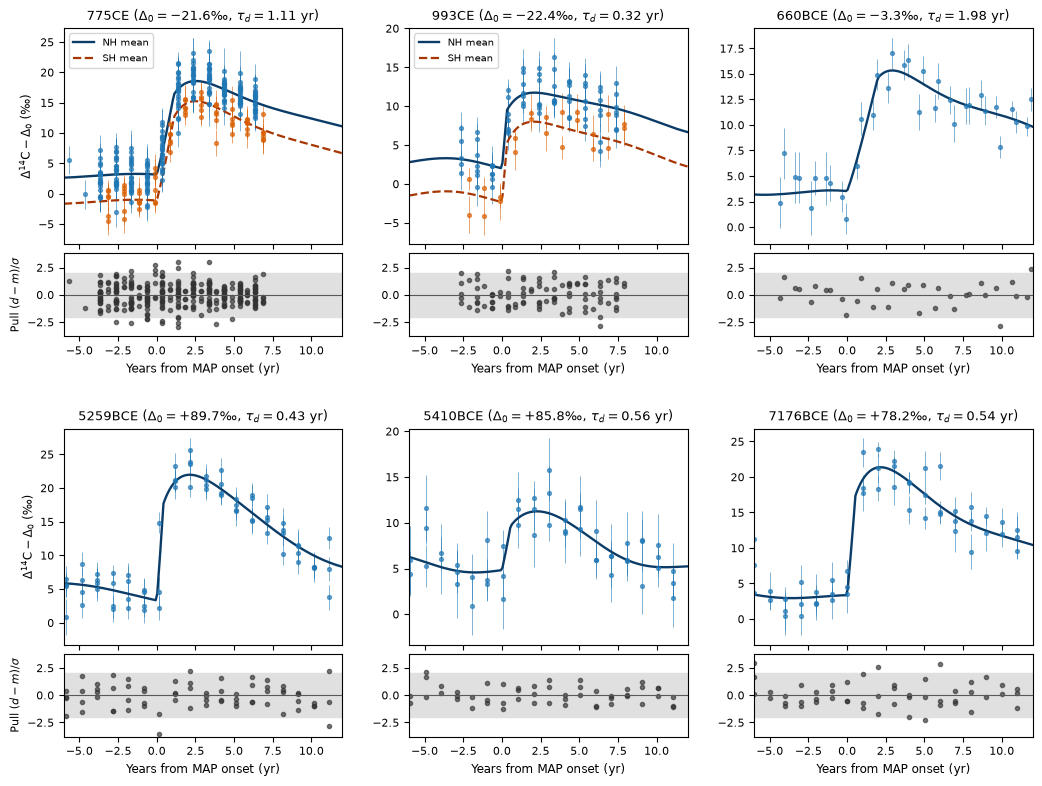

In [3]:
fig = plt.figure(figsize=(12.5, 9.2))
outer = fig.add_gridspec(2, 3, wspace=0.24, hspace=0.30)
for idx, ev in enumerate(EVENTS):
    f = fits[ev]
    ds, lp_nh, lp_sh = f["ds"], f["lp_nh"], f["lp_sh"]
    inner = outer[idx // 3, idx % 3].subgridspec(2, 1, height_ratios=[3.0, 1.15], hspace=0.06)
    ax_top = fig.add_subplot(inner[0])
    ax_bot = fig.add_subplot(inner[1], sharex=ax_top)
    t_rel_fine = np.asarray(f["t_fine"]) - f["ts"]
    d0 = f["d0"]
    lab_off = np.asarray(lp_nh.offset_lab_means) if lp_nh.offset_lab_means is not None else np.zeros(ds.n_series)
    for s_i, s in enumerate(ds.series):
        dt_s = np.asarray(s.t_midpoints) - f["ts"]
        mask = (dt_s >= -6.0) & (dt_s <= 12.0)
        col = "#1f77b4" if s.hemisphere == "north" else "#d95f02"
        y_adj = np.asarray(s.d14c)[mask] - d0 - float(lab_off[s_i])
        ax_top.errorbar(dt_s[mask], y_adj, yerr=np.asarray(s.sigma_d14c)[mask], fmt="o", ms=2.8, lw=0.6, alpha=0.65, color=col)
    ax_top.plot(t_rel_fine, np.asarray(lp_nh.d14c_fine_mean) - d0, color="#0b3c68", lw=1.7, label="NH mean")
    if lp_sh is not None:
        ax_top.plot(t_rel_fine, np.asarray(lp_sh.d14c_fine_mean) - d0, color="#a63603", lw=1.6, ls="--", label="SH mean")
        ax_top.legend(fontsize=7.5, loc="upper left")
    pulls = np.asarray((ds.d14c_flat - lp_nh.ring_pred_mean) / ds.sigma_flat)
    dt_all = np.asarray(ds.t_midpoints_flat) - f["ts"]
    m_all = (dt_all >= -6.0) & (dt_all <= 12.0)
    ax_bot.axhline(0.0, color="0.35", lw=0.8)
    ax_bot.axhspan(-2.0, 2.0, color="0.88", zorder=0)
    ax_bot.scatter(dt_all[m_all], pulls[m_all], s=9, color="#333333", alpha=0.65)
    ax_bot.set_ylim(-3.8, 3.8)
    ax_bot.set_xlabel("Years from MAP onset (yr)", fontsize=8.5)
    if idx % 3 == 0:
        ax_top.set_ylabel(r"$\Delta^{14}\mathrm{C} - \Delta_0$ (‰)", fontsize=8.5)
        ax_bot.set_ylabel(r"Pull $(d - m)/\sigma$", fontsize=8.0)
    ax_top.set_title(f"{ev} ($\\Delta_0={d0:+.1f}$‰, $\\tau_d={f['dur']:.2f}$ yr)", fontsize=9.5)
    ax_top.tick_params(labelbottom=False, labelsize=8)
    ax_bot.tick_params(labelsize=8)
    ax_top.set_xlim(-6.0, 12.0)
plt.show()


Reporting cosmic-ray yield in years of steady-state production depends directly on the reference baseline: during a mid-Holocene geomagnetic low with positive `baseline_d14c`, the ambient steady-state production rate exceeds the 1950 CE oxalic-acid standard (`relative_to="standard"`). Passing `baseline_d14c_permil` to `RadiocarbonModel.fluence_q0_years` rescales the normalized spike yield (`Y_amb`) relative to the pre-industrial standard yield (`Y_std`) via the contemporary ambient production rate `q_0(t_ev) = q_std * (1 + Delta_0 / 1000)`:

$$Y_{\mathrm{amb}} = \frac{F}{q_0(t_{\mathrm{ev}})} = \frac{Y_{\mathrm{std}}}{1 + \Delta_0 / 1000}$$

Near-modern events (`775CE`, `993CE`, `660BCE`) shift by at most `2.3%`, whereas the mid-Holocene geomagnetic-low events (`5259BCE`, `5410BCE`, `7176BCE`) decrease by `7.3%` to `8.2%`, placing the three largest Holocene events (`775CE`, `5259BCE`, `7176BCE`) within `3.5` to `3.9` ambient production-years.

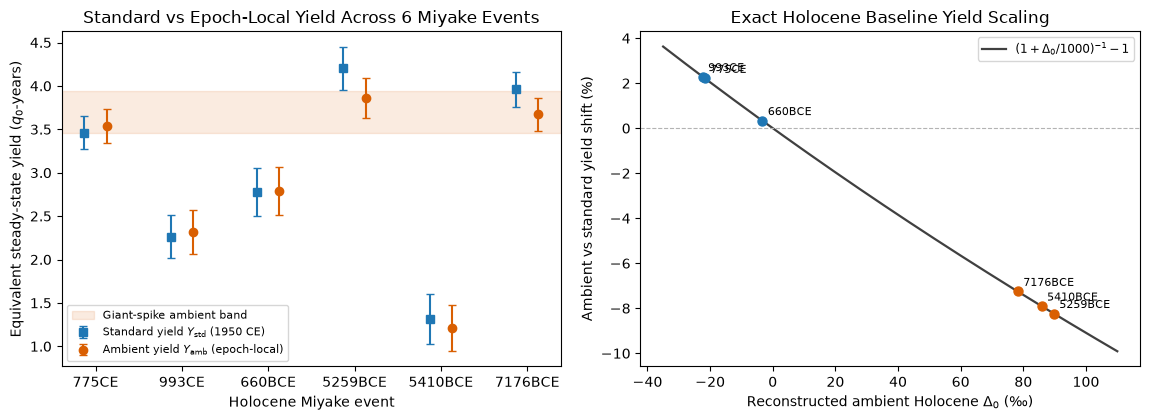

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.6, 4.3))
x_pos = np.arange(len(EVENTS))
y_std_v = np.array([fits[e]["y_std"] for e in EVENTS])
y_amb_v = np.array([fits[e]["y_amb"] for e in EVENTS])
y_std_err = np.array([float(tt.RadiocarbonModel.fluence_q0_years(fits[e]["fl_sd"])) for e in EVENTS])
y_amb_err = np.array([float(tt.RadiocarbonModel.fluence_q0_years(fits[e]["fl_sd"], baseline_d14c_permil=fits[e]["d0"])) for e in EVENTS])
ax1.errorbar(x_pos - 0.13, y_std_v, yerr=y_std_err, fmt="s", color="#1f77b4", capsize=3, label=r"Standard yield $Y_{\mathrm{std}}$ (1950 CE)")
ax1.errorbar(x_pos + 0.13, y_amb_v, yerr=y_amb_err, fmt="o", color="#d95f02", capsize=3, label=r"Ambient yield $Y_{\mathrm{amb}}$ (epoch-local)")
giant_y = [fits[e]["y_amb"] for e in ("775CE", "5259BCE", "7176BCE")]
ax1.axhspan(min(giant_y) - 0.08, max(giant_y) + 0.08, color="#d95f02", alpha=0.12, label="Giant-spike ambient band")
ax1.set_xticks(x_pos, EVENTS)
ax1.set_xlabel("Holocene Miyake event")
ax1.set_ylabel(r"Equivalent steady-state yield ($q_0$-years)")
ax1.set_title("Standard vs Epoch-Local Yield Across 6 Miyake Events")
ax1.legend(fontsize=8.0, loc="lower left")
d_grid = np.linspace(-35.0, 110.0, 200)
ax2.plot(d_grid, 100.0 * (1.0 / (1.0 + d_grid / 1000.0) - 1.0), color="0.25", lw=1.6, label=r"$(1 + \Delta_0/1000)^{-1} - 1$")
ax2.axhline(0.0, color="0.7", lw=0.8, ls="--")
for ev in EVENTS:
    d0 = fits[ev]["d0"]
    pct = 100.0 * (fits[ev]["y_amb"] / fits[ev]["y_std"] - 1.0)
    ax2.scatter([d0], [pct], s=42, color="#d95f02" if d0 > 40.0 else "#1f77b4", zorder=4)
    ax2.annotate(ev, (d0, pct), xytext=(4, 4), textcoords="offset points", fontsize=8.0)
ax2.set_xlabel(r"Reconstructed ambient Holocene $\Delta_0$ (‰)")
ax2.set_ylabel("Ambient vs standard yield shift (%)")
ax2.set_title("Exact Holocene Baseline Yield Scaling")
ax2.legend(fontsize=8.5)
fig.tight_layout()
plt.show()


Multi-laboratory compilations exhibit heterogeneous excess scatter beyond quoted AMS counting statistics. Pairing a reflecting-boundary DCT-II `GaussianField` ([Enßlin et al. (2009)](https://doi.org/10.1103/PhysRevD.80.105005)) with `fit_ift_field` and [MacKay (1992)](https://doi.org/10.1162/neco.1992.4.3.415)'s closed-form `error_scale(..., by_series=True)` estimator (which equates expected posterior trace degrees of freedom to weighted squared residuals at the marginal-evidence stationary point) audits each constituent tree-ring series without MCMC, isolating over-dispersed records for empirical-Bayes uncertainty rescaling via `Dataset.with_error_scale`.

In [5]:
audit_lines = []
for ev in ("993CE", "5259BCE"):
    ds = datasets[ev]
    t0, t1 = ds.time_span
    f_prod = tt.ProductionSum(
        steady=tt.SteadyProduction(),
        field=tt.GaussianField(jnp.zeros(96), t0 - 5.0, t1 + 2.0, sigma=0.12, length_yr=6.0, order=2.0),
        spike=tt.MiyakeSpike(t_start=fits[ev]["ts"], duration=fits[ev]["dur"], fluence=fits[ev]["fl"], profile="boxcar"),
    )
    ift_res = tt.fit_ift_field(tt.RadiocarbonModel(cbm, f_prod), ds)
    s_glob = float(tt.error_scale(ift_res, ds, by_series=False))
    by_s = tt.error_scale(ift_res, ds, by_series=True)
    top_str = ", ".join(f"{k}: {v:.2f}x" for k, v in sorted(by_s.items(), key=lambda kv: -kv[1]))
    audit_lines.append(f"{ev} (ln Z = {float(ift_res.log_evidence):.1f}, global scale = {s_glob:.2f}x):\n  {top_str}")
print("\n".join(audit_lines))


993CE (ln Z = -228.5, global scale = 1.13x):
  Büntgen18_SWE02: 1.38x, Büntgen18_SWE03: 1.33x, Büntgen18_SWE04: 1.28x, Büntgen18_MON05: 1.23x, Büntgen18_SWE01: 1.21x, Büntgen18_DAR01: 1.13x, Büntgen18_PAT03: 0.91x, Büntgen18_CHI01: 0.91x, Büntgen18_ALT02: 0.62x
5259BCE (ln Z = -231.6, global scale = 1.20x):
  Brehm21_USABristlecone: 1.38x, Brehm21_SibirianLarch: 1.21x, Brehm21_AlpineLarch: 1.16x, Brehm21_IrishOak: 1.04x


Across nine millennia of tree-ring radiocarbon data, `ticktack 2.0`'s analytical marginalization of hierarchical Holocene baselines, exact two-hemisphere seasonal window integration, and IFT per-series noise calibration eliminate legacy boundary-clamping and calendar biases. Accounting for the elevated mid-Holocene ambient radiocarbon inventory reduces the apparent `q0`-year yields of `5259BCE`, `5410BCE`, and `7176BCE` by `7.3%` to `8.2%` relative to the 1950 CE standard while leaving absolute physical fluences (`atoms cm^-2`) invariant, placing the three largest Holocene events (`775CE`, `5259BCE`, `7176BCE`) within `3.5` to `3.9` ambient production-years.